# Univariate Linear Regression

## Part 1: Dataset Loading and Preprocessing
### 1.1 Univariate Dataset
Dataset: Diamonds. Feature: carat. Target: price.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv')
print(d.head())
d.info()

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: f

In [2]:
print(d.isnull().sum())
d = d.dropna()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [3]:
X = d['carat'].values
y = d['price'].values

In [4]:
np.random.seed(42)
i = np.random.permutation(len(X))
n = int(0.8 * len(X))
x1, y1 = X[i[:n]], y[i[:n]]
x2, y2 = X[i[n:]], y[i[n:]]

u, s = x1.mean(), x1.std()
x1 = (x1 - u) / s
x2 = (x2 - u) / s

print(x1[:5], x1.mean(), x1.std())
print(len(x1), len(x2))

[-1.17735748 -0.46021405 -0.83987822 -0.77660086  1.58575395] -1.962752458810807e-16 0.9999999999999998
43152 10788


## Part 2: Implementing Linear Regression from Scratch
### 2.1 Hypothesis Function
ŷ = mx + c

In [5]:
def h(m, c, x):
    return m * x + c

### 2.2 Cost Function
J = (1/n) Σ (y − ŷ)²

In [6]:
def J(m, c, x, y):
    return np.mean((y - h(m, c, x)) ** 2)

### 2.3 Gradient Descent
θⱼ := θⱼ − α ∂J/∂θⱼ

Learning rate: 0.1. The feature is scaled, so this rate converges quickly without overshooting.

In [7]:
def gd(x, y, a, k):
    m, c = 0.0, 0.0
    H = []
    for _ in range(k):
        e = h(m, c, x) - y
        m = m - a * 2 * np.mean(e * x)
        c = c - a * 2 * np.mean(e)
        H.append(J(m, c, x, y))
    return m, c, H

## Part 3: Optimal Parameters and Visualization
### 3.1 Training and Optimal Parameters

In [8]:
a, k = 0.1, 1000
m, c, H = gd(x1, y1, a, k)

print('m =', m)
print('c =', c)
print('Final MSE =', H[-1])
print('Iterations =', k)
print('First MSE =', H[0])

m = 3678.617481221209
c = 3936.291481275491
Final MSE = 2424445.2802034765
Iterations = 1000
First MSE = 21001480.287376773


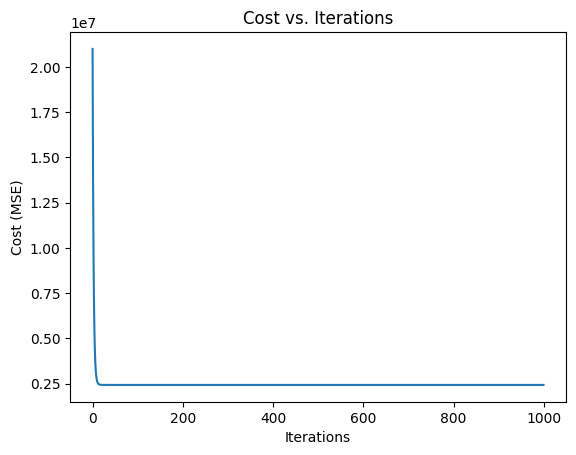

In [9]:
plt.plot(range(len(H)), H)
plt.xlabel("Iterations")
plt.ylabel("Cost (MSE)")
plt.title("Cost vs. Iterations")
plt.show()

### 3.2 Visualization

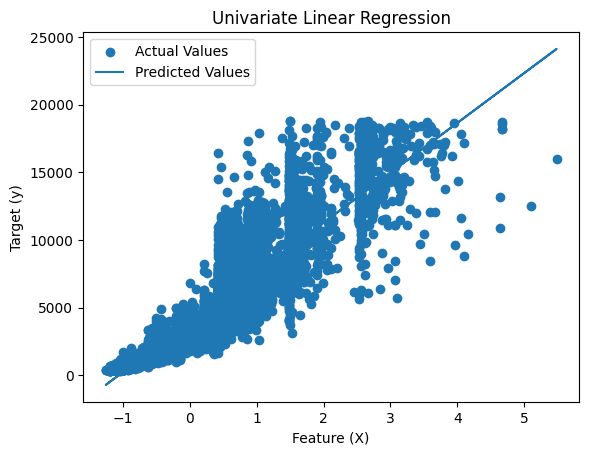

In [10]:
p = h(m, c, x2)

plt.scatter(x2, y2, label="Actual Values")
plt.plot(x2, p, label="Predicted Values")
plt.xlabel("Feature (X)")
plt.ylabel("Target (y)")
plt.title("Univariate Linear Regression")
plt.legend()
plt.show()

## Part 4: Theory Questions

**Q1. Why can feature scaling be useful when training Linear Regression using Gradient Descent? What can happen if the feature values have very different scales?**

Gradient Descent uses one learning rate for all parameters. If feature values are on very different scales, the gradients have very different sizes and due to it the cost surface becomes like a long narrowed valley. The updates then zigzag or diverge. Or we can use a small learning rate and convergence becomes slow. Scaling makes the updates balanced, so training is faster and more stable.

**Q2. What is the effect of choosing a learning rate that is too small or too large? Explain how each choice can affect the cost during training.**

If a learning rate is too small it makes very small updates causing the cost to decrease very slowly and needs many iterations. If a learning rate is too large it overshoots the minimum causing the cost to oscillate or increase and can diverge.